In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("all_tickets_processed_improved_v3.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (47837, 2)


,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['Document', 'Topic_group']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB

Missing values:
Document       0
Topic_group    0
dtype: int64


In [3]:
print("Ticket categories:")
print(df["Topic_group"].value_counts())

Ticket categories:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64


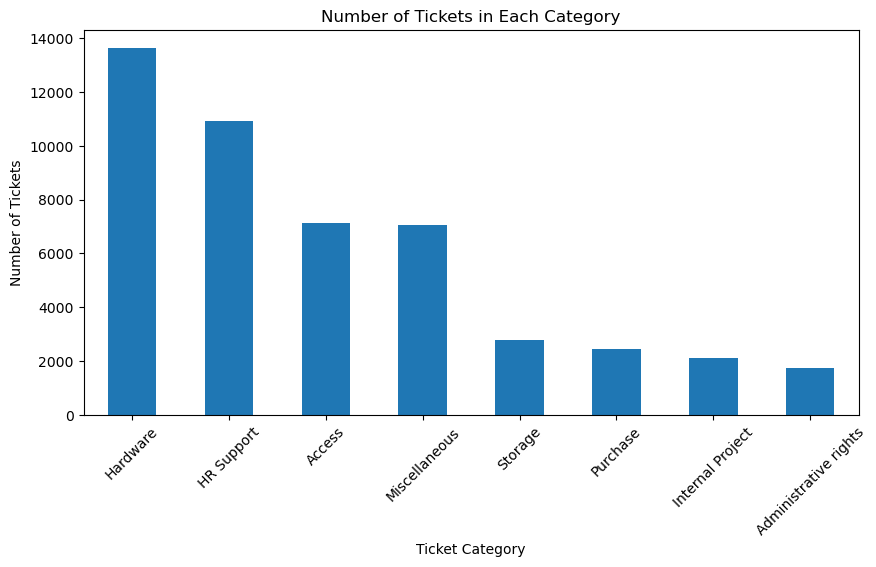

In [4]:
df["Topic_group"].value_counts().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Number of Tickets in Each Category")
plt.xlabel("Ticket Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.show()

In [5]:
df = df.dropna(subset=["Document", "Topic_group"])

df["Document"] = df["Document"].astype(str)
df["Topic_group"] = df["Topic_group"].astype(str)

df = df.drop_duplicates()

print("Data cleaned successfully!")
print("Remaining rows:", len(df))

Data cleaned successfully!
Remaining rows: 47837


In [6]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["Cleaned_Text"] = df["Document"].apply(clean_text)

display(df[["Document", "Cleaned_Text", "Topic_group"]].head())

,Document,Cleaned_Text,Topic_group
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...,Miscellaneous


In [7]:
from sklearn.model_selection import train_test_split

X = df["Cleaned_Text"]
y = df["Topic_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 38269
Testing data: 9568


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Model Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Model Accuracy: 0.8487667224080268

Classification Report:
                       precision    recall  f1-score   support

               Access       0.91      0.87      0.89      1425
Administrative rights       0.89      0.65      0.75       352
           HR Support       0.86      0.85      0.85      2183
             Hardware       0.78      0.89      0.83      2724
     Internal Project       0.91      0.80      0.85       424
        Miscellaneous       0.82      0.82      0.82      1412
             Purchase       0.98      0.87      0.92       493
              Storage       0.94      0.84      0.89       555

             accuracy                           0.85      9568
            macro avg       0.89      0.82      0.85      9568
         weighted avg       0.85      0.85      0.85      9568



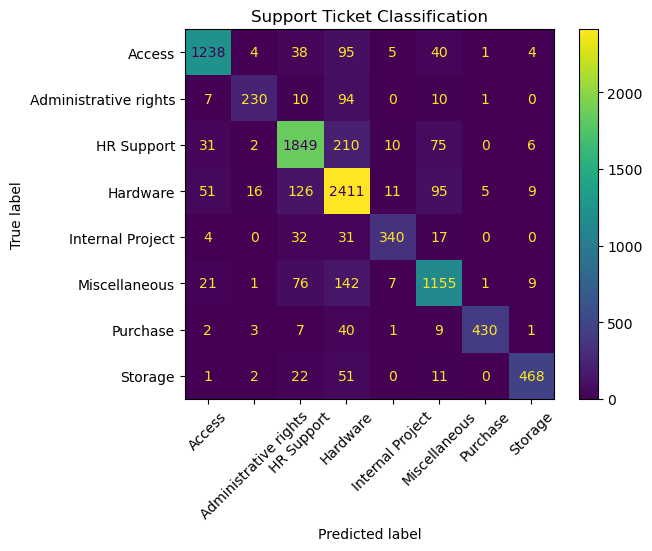

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Support Ticket Classification")
plt.show()

In [11]:
new_ticket = "I cannot access my account and need help logging in."

cleaned_ticket = clean_text(new_ticket)

prediction = model.predict([cleaned_ticket])

print("Ticket:", new_ticket)
print("Predicted Category:", prediction[0])

Ticket: I cannot access my account and need help logging in.
Predicted Category: Access
